Determining the number of active minipix (minipix occupied by sources) as a function of source limiting magnitude in (a) a blue $g$-like passband, and (b) limiting magnitude in any optical PanSTARRS $grizY$ filter (because not all PanSTARRS objects have g-band photometry).

*Run this notebook with the hdps virtual environment*

Steps:
- get reference catalog(s), apply appropriate filters ([dec>=-20],[gmag<22])
- lookup minipix idx for each source
- bin sources in gmag
- for each bin:
    - starting at brightest bin, generate a list of all unique minipix idx and record its length
    - if not first bin in sequence, add this bin's unique minipix list to the accumulated list of unique minipix for all preceeding bins and re-unique-ify the list, then record its length
- fit a 2D model to (mag bins) vs (fraction of unique minipix occupied by sources brighter than mag bin)

In [2]:
import dask
from dask.distributed import Client
import lsdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as scistat #binned_statistic
from scipy.optimize import curve_fit
import scipy as sp


from hdps.skymap import SegmentationScheme,TanSegmentLookup,composite_id_to_radec

from hdps.catalogs import ATLASRefcat2,PanSTARRS,AICRefcat,AICRefcatBuilder

In [7]:
ps = lsdb.open_catalog("/net/scratch/kmfas/panstarrs")
ps_filt = ps.query("gMeanApMag < 22.0 or iMeanApMag < 22.0")
ps_filt

,decMean,decMeanErr,epochMean,gFlags,gMeanPSFMag,gMeanPSFMagErr,iFlags,iMeanPSFMag,iMeanPSFMagErr,nDetections,ng,ni,nr,ny,nz,objID,objInfoFlag,qualityFlag,raMean,raMeanErr,rFlags,rMeanPSFMag,rMeanPSFMagErr,surveyID,yFlags,yMeanPSFMag,yMeanPSFMagErr,zFlags,zMeanPSFMag,zMeanPSFMagErr
npartitions=9577,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",double[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int64[pyarrow],int32[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow]
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


In [8]:
ps

,decMean,decMeanErr,epochMean,gFlags,gMeanPSFMag,gMeanPSFMagErr,iFlags,iMeanPSFMag,iMeanPSFMagErr,nDetections,ng,ni,nr,ny,nz,objID,objInfoFlag,qualityFlag,raMean,raMeanErr,rFlags,rMeanPSFMag,rMeanPSFMagErr,surveyID,yFlags,yMeanPSFMag,yMeanPSFMagErr,zFlags,zMeanPSFMag,zMeanPSFMagErr
npartitions=9577,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",double[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int64[pyarrow],int32[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow]
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


# .Retrieving catalogs

## ..ATLAS-Refcat2
Using this catalog to compare results to previous minipix occupancy estimation, which used the HEALPix scheme (sky tiling scheme had not yet been determinded)

In [2]:
# open the 1% fraction of HATS-ed ATLAS for testing (faster than full cat)
print("opening ATLAS-Refcat2 at ",ATLASRefcat2.DEFAULT_PATH," with filters ",ATLASRefcat2(ATLASRefcat2.DEFAULT_PATH).filters+[["g",">=",15]])
atlas = ATLASRefcat2(ATLASRefcat2.DEFAULT_PATH)
atlas.filters = atlas.filters+[["g",">=",15]]
atlas.catalog = lsdb.open_catalog(atlas.path,filters=atlas.filters)
atlas.catalog

opening ATLAS-Refcat2 at  /net/scratch/kmfas/atlas_refcat2/atlas_0_01  with filters  [['g', '<=', 19.0], ['dec', '>=', -20.0], ['g', '>=', 15]]


,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256
npartitions=21693,,,,,,,,,,,,
"Order: 4, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow]
"Order: 4, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...


In [3]:
# open a cone of ATLAS:
rad_deg = 50
rad_arcsec = rad_deg*60*60 # 5000
atlas_cone = lsdb.open_catalog(atlas.path,search_filter=lsdb.ConeSearch(ra=40, dec=30, radius_arcsec=rad_arcsec),filters=atlas.filters)
atlas_cone

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256
npartitions=1884,,,,,,,,,,,,
"Order: 4, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow]
"Order: 4, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 4, Pixel: 2302",...,...,...,...,...,...,...,...,...,...,...,...
"Order: 4, Pixel: 2303",...,...,...,...,...,...,...,...,...,...,...,...


In [4]:
# open a partition of ATLAS:
# fully load a single partition of ATLAS
ordr = 3     # healpix order of partition you want (I looked this pair up in my notebook for testing mapping functions to partitions with LSDB)
pixid = 368  # ID of partition you want
atlas_pix_lookup = lsdb.open_catalog(atlas.path,search_filter=lsdb.PixelSearch((ordr,pixid)),filters=atlas.filters)
atlas_single_part = atlas_pix_lookup.compute()

Computing Catalog:   0%|          | 0/49 [00:00<?, ?it/s]

## .. PanSTARRS

In [ ]:
panstarrs_path = "/net/scratch/kmfas/panstarrs"
bright_mag_cut = 15.0
faint_mag_cut = 22.0
dec_cut = -20

panstarrs_columns = ["ra","dec","gMeanApMag","rMeanApMag","iMeanApMag","zMeanApMag","yMeanApMag","pmra","pmdec"]

# get PanSTARRS sources for which g-band photometry passes magnitude cuts
# (to keep the focus on Argus_beta-like photometry)
panstarrs_g = PanSTARRS(panstarrs_path)
panstarrs_g.filters = [['gMeanApMag', '>=', bright_mag_cut],
                       ['gMeanApMag', '<=', faint_mag_cut],
                       ['decMean', '>=', dec_cut]]
panstarrs_g.catalog=lsdb.open_catalog(panstarrs_g.path,filters=panstarrs_g.filters,columns=panstarrs_g.columns)

# get PanSTARRS sources for which the photometry in any filter passes mag cuts
# (in the same vein as ATLAS source selection from PS)
panstarrs_any = PanSTARRS(panstarrs_path)
panstarrs_any.filters = [['gMeanApMag', '>=', bright_mag_cut],['gMeanApMag', '<=', faint_mag_cut],
                         ['rMeanApMag', '>=', bright_mag_cut],['rMeanApMag', '<=', faint_mag_cut],
                         ['iMeanApMag', '>=', bright_mag_cut],['iMeanApMag', '<=', faint_mag_cut],
                         ['zMeanApMag', '>=', bright_mag_cut],['zMeanApMag', '<=', faint_mag_cut],
                         ['yMeanApMag', '>=', bright_mag_cut],['yMeanApMag', '<=', faint_mag_cut],
                         ['decMean', '>=', dec_cut]]
panstarrs_any.catalog=lsdb.open_catalog(panstarrs_any.path,filters=panstarrs_any.filters,columns=panstarrs_any.columns)

In [4]:
panstarrs_any.catalog

,objID,raMean,decMean,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr
npartitions=9577,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow]
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


# .Testing through each step:

## .. Binning sources in magnitude

### ...Data binning speed tests

Our options are __[scipy.stats.binned_statistic()](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binned_statistic.html)__, __[numpy.digitize()](https://numpy.org/doc/stable/reference/generated/numpy.digitize.html)__, __[numpy.histogram](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html)__


<font color="#e69138">Show how each method can be used:</font>

In [141]:
data = np.random.rand(100)

In [143]:
# scipy.stats.binned_statistic()
bin_edges = [0,0.2,0.4,0.6,0.8,1.0] # 10 # can be scalar (number of bins) or a sequence (bin edges, including rightmost edge)
bins = scistat.binned_statistic(data, data, bins=bin_edges, statistic="count", range=(0, 1)) # returns statistic/bin, bin_edges, binnumber for each data point
bins

BinnedStatisticResult(statistic=array([22., 19., 16., 20., 23.]), bin_edges=array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]), binnumber=array([5, 5, 1, 2, 5, 1, 1, 4, 3, 5, 4, 1, 2, 5, 2, 5, 3, 4, 5, 5, 5, 5,
       2, 4, 4, 4, 5, 3, 1, 1, 4, 3, 4, 1, 2, 5, 2, 1, 4, 2, 5, 4, 1, 5,
       4, 2, 4, 3, 1, 1, 2, 1, 5, 5, 4, 4, 1, 3, 3, 5, 2, 2, 4, 5, 2, 3,
       2, 3, 4, 1, 1, 1, 3, 4, 1, 5, 2, 5, 2, 1, 1, 2, 4, 3, 1, 5, 2, 1,
       5, 3, 3, 3, 2, 1, 3, 4, 2, 3, 4, 5]))

In [144]:
# numpy.digitize
bin_edges = [0,0.2,0.4,0.6,0.8,1.0] 
bin_indices = np.digitize(data,bin_edges,right=True)
bin_indices,np.histogram(bin_indices,bins=len(bin_edges)-1)[0]

(array([5, 5, 1, 2, 5, 1, 1, 4, 3, 5, 4, 1, 2, 5, 2, 5, 3, 4, 5, 5, 5, 5,
        2, 4, 4, 4, 5, 3, 1, 1, 4, 3, 4, 1, 2, 5, 2, 1, 4, 2, 5, 4, 1, 5,
        4, 2, 4, 3, 1, 1, 2, 1, 5, 5, 4, 4, 1, 3, 3, 5, 2, 2, 4, 5, 2, 3,
        2, 3, 4, 1, 1, 1, 3, 4, 1, 5, 2, 5, 2, 1, 1, 2, 4, 3, 1, 5, 2, 1,
        5, 3, 3, 3, 2, 1, 3, 4, 2, 3, 4, 5]),
 array([22, 19, 16, 20, 23]))

In [48]:
# numpy.histogram; don't use this, it only returns count/bin and bin edges!
bin_edges = [0,0.2,0.4,0.6,0.8,1.0] # 10# can be scalar (number of bins) or a sequence (bin edges, including rightmost edge)
np.histogram(data,bin_edges)

(array([21, 22, 22, 14, 21]), array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]))

<font color="#e69138">Write functions to apply each method to a dataframe, to be used with map_partitions() on a lazily-loaded HATS-ed catalog:</font>

In [ ]:
def bin_mags(dframe,col,meth,count=True):
    dframe_copy = dframe.copy()
    #print("length of partition = ",len(dframe_copy))
    data = dframe_copy[col]
    bin_edges = np.arange(15,22.5,0.5)
    if meth=="scipy.binstat":
        bins = scistat.binned_statistic(data, data, bins=bin_edges, statistic="count", range=(0, 1))
        bin_nums = bins.binnumber
        if count:
            counts = bins.statistic
    elif meth=="numpy.dig":
        bin_nums = np.digitize(data,bin_edges,right=True)
        if count:
            counts = np.histogram(bin_nums,bins=len(bin_edges)-1)[0]
    else:
        print(f"method {meth} not supported")
    dframe_copy['mag_bins'] = bin_nums # make a column with bin number
    if count: 
        return(dframe_copy,counts)
    else:
        return(dframe_copy)

<font color="#e69138">Use function on single partition of ATLAS:</font>

In [160]:
bin_mags(atlas_single_part,"g","scipy.binstat",count=False)

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins
_healpix_29,,,,,,,,,,,,,
1657325513743157866,23020,90.006208,0.091356,1.13,-1.42,-0.2,17.496,16.517,16.01,5888,23552,376832,5
1657325536932057554,33355,89.985974,0.09594,0.69,-0.52,5.82,17.479,16.626,16.181,5888,23552,376832,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1661827272758578812,119567,90.013518,9.480139,1.1,5.27,-3.58,19.72,18.446,17.76,5903,23615,377855,10
1661827954336513510,201498,89.947741,9.530316,1.41,1.81,0.18,20.508,19.446,18.91,5903,23615,377855,12


In [161]:
bin_mags(atlas_single_part,"g","numpy.dig",count=False)

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins
_healpix_29,,,,,,,,,,,,,
1657325513743157866,23020,90.006208,0.091356,1.13,-1.42,-0.2,17.496,16.517,16.01,5888,23552,376832,5
1657325536932057554,33355,89.985974,0.09594,0.69,-0.52,5.82,17.479,16.626,16.181,5888,23552,376832,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1661827272758578812,119567,90.013518,9.480139,1.1,5.27,-3.58,19.72,18.446,17.76,5903,23615,377855,10
1661827954336513510,201498,89.947741,9.530316,1.41,1.81,0.18,20.508,19.446,18.91,5903,23615,377855,12


<font color="#e69138">Use function on full catalog with map_partitions():</font>

In [118]:
# make a meta information object:
atlas_cols = list(atlas.catalog.columns)+["mag_bins"]
atlas_dtypes = list(atlas.catalog.dtypes)+ ["int64"]
atlas_binned_meta = pd.DataFrame(
            {col: pd.Series(dtype=dtp) for col, dtp in zip(atlas_cols, atlas_dtypes)}
        )

<font color="#e69138">Apply to cone ATLAS:</font>

In [ ]:
binned_cone_scipy = atlas_cone.map_partitions(bin_mags,"g","scipy.binstat",False,meta=atlas_binned_meta)
binned_cone_scipy.compute()

Computing Catalog:   0%|          | 0/11305 [00:00<?, ?it/s]

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins
_healpix_29,,,,,,,,,,,,,
60097340777969,4284,45.008002,0.888571,3.88,-59.51,-64.33,9.963,9.298,9.026,0,0,13,0
60119873780780,4292,45.024515,0.90671,2.43,-1.52,-34.37,13.412,12.816,12.618,0,0,13,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2593878980698354953,5239,45.698569,-1.301505,2.33,10.29,-9.97,14.149,13.543,13.327,9215,36861,589779,0
2594028974828159598,1847,45.495972,-0.514618,1.02,28.06,-1.46,14.965,14.538,14.372,9215,36863,589813,0


In [163]:
binned_cone_numpy = atlas_cone.map_partitions(bin_mags,"g","numpy.dig",False,meta=atlas_binned_meta)
binned_cone_numpy.compute()

Computing Catalog:   0%|          | 0/11305 [00:00<?, ?it/s]

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins
_healpix_29,,,,,,,,,,,,,
60097340777969,4284,45.008002,0.888571,3.88,-59.51,-64.33,9.963,9.298,9.026,0,0,13,0
60119873780780,4292,45.024515,0.90671,2.43,-1.52,-34.37,13.412,12.816,12.618,0,0,13,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2593878980698354953,5239,45.698569,-1.301505,2.33,10.29,-9.97,14.149,13.543,13.327,9215,36861,589779,0
2594028974828159598,1847,45.495972,-0.514618,1.02,28.06,-1.46,14.965,14.538,14.372,9215,36863,589813,0


<font color="#e69138">Apply to full ATLAS:</font>

In [180]:
atlas_binned_scipy = atlas.catalog.map_partitions(bin_mags,"g","scipy.binstat",False,meta=atlas_binned_meta)
atlas_binned_scipy.compute()

Computing Catalog:   0%|          | 0/108466 [00:00<?, ?it/s]

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins
_healpix_29,,,,,,,,,,,,,
14812298314436,4334,45.121224,0.462284,3.55,18.47,-37.28,15.583,14.533,14.067,0,0,3,2
22600017436762,6202,45.487836,0.516156,0.98,-7.18,2.32,17.794,17.019,16.67,0,0,5,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3458763614671860880,26140,314.968588,-0.102586,0.33,-0.51,-0.3,17.525,17.141,16.997,12287,49151,786431,6
3458763823364429095,37146,315.066142,-0.061172,0.62,1.33,-6.02,17.832,17.077,16.785,12287,49151,786431,6


In [ ]:
atlas_binned_numpy = atlas.catalog.map_partitions(bin_mags,"g","numpy.dig",False,meta=atlas_binned_meta)
atlas_binned_numpy.compute()

Computing Catalog:   0%|          | 0/108466 [00:00<?, ?it/s]

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins
_healpix_29,,,,,,,,,,,,,
60097340777969,4284,45.008002,0.888571,3.88,-59.51,-64.33,9.963,9.298,9.026,0,0,13,0
60119873780780,4292,45.024515,0.90671,2.43,-1.52,-34.37,13.412,12.816,12.618,0,0,13,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3458724590902275262,18124,315.12815,-0.516714,1.24,0.59,-8.66,14.937,14.508,14.356,12287,49151,786422,0
3458725022188311511,18419,315.388755,-0.562243,0.61,2.92,-4.41,14.8,14.415,14.296,12287,49151,786423,0


### Testing out lsdb.to_delayed() instead of lsdb.map_partitions()

Why?  Basically, when binning sources in magnitude, I also want the bin counts (number of sources per mag bin).  But if I apply my binning function to the partitions of a catalog with lsdb.map_partitions(), I am limited to only returning the resulting dataframe with an added bins colunm, and not a list of count/bin (because of the nature of lsdb.map_partitions(), which uses dask.map_partition(), which only "knows" how to return a dataframe) __[lsdb docs](https://docs.lsdb.io/en/latest/tutorials/pre_executed/map_partitions.html)__.  

There are a few options:

(1) I could simply create a sequence of these bin counts and add that as a column to the dataframe; each row will have a value in the "mag_bins" column that indicate which bin it belongs in.  For each row, i could simply have another column that indicates the bin count for the bin that the source belongs in.  This would be.....annoying, because that is super duplication and, for the entire catalog, will take up a certain unnecessary amount of space.  I don't want to do that.
- I will note that there's an option to return a reduced dataframe if you're calculating per-partition statistics or someething, but I want to return both the per-partition bin count *and* the catalog dataframe + mag_bin column.  This alternate application doesn't allow for both simultaneously.

(2) Instead of using __[`lsdb.map_partitions()`](https://docs.lsdb.io/en/latest/reference/api/lsdb.catalog.Catalog.map_partitions.html)__, I could use __[`lsdb.to_delayed()`](https://docs.lsdb.io/en/latest/reference/api/lsdb.catalog.Catalog.to_delayed.html)__, which uses __[Dask Delayed](https://docs.dask.org/en/stable/delayed.html)__ and is less-documented but here's what it does:
- returns a list of "Dask Delayed" objects for each partition in the catalog
- to use again with LSDB, the delayed objects have to be converted to a Dask DataFrame and used with extra metadata to construct an LSDB Dataset.  what?  

<font color="#e69138">Let's try it out:</font>

In [5]:
delayed_atlas = atlas.catalog.to_delayed()
results = [dask.delayed(bin_mags)(p,"g","scipy.binstat",True) for p in delayed_atlas]
atlas_binned = [r[0] for r in results]
partition_counts = [r[1] for r in results]

In [6]:
computed_atlas_binned, computed_partition_counts = dask.compute(atlas_binned,partition_counts)

<font color="#e69138">So, already before this thing has even completed I can tell you that it takes way longer than using `lsdb.map_partitions()` to do the same thing, so idk about that.  About 2x longer, actually.  But since I don't have to do this a whole lot of times, that is acceptable to me.  </font>

In [184]:
computed_atlas_binned[0]

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins
_healpix_29,,,,,,,,,,,,,
14812298314436,4334,45.121224,0.462284,3.55,18.47,-37.28,15.583,14.533,14.067,0,0,3,2
22600017436762,6202,45.487836,0.516156,0.98,-7.18,2.32,17.794,17.019,16.67,0,0,5,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095111764427415,17602,44.646966,4.176627,0.22,14.34,-9.31,18.733,18.324,18.127,3,15,248,8
1109167694277157,10694,44.988039,4.269202,0.18,7.33,-1.36,18.015,17.523,17.29,3,15,252,7


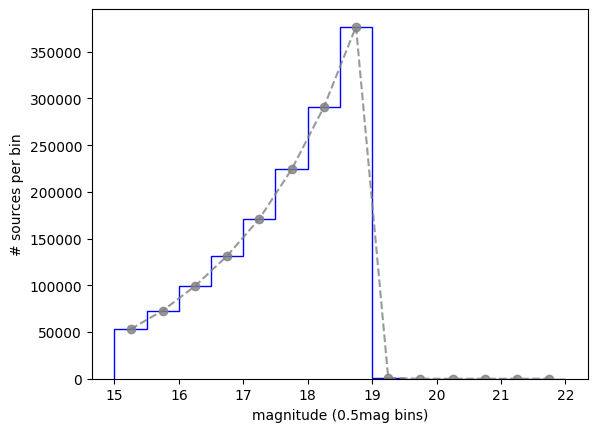

In [24]:
plt.stairs(sum(computed_partition_counts),np.arange(15,22.5,0.5),color="blue")
plt.plot(np.arange(15.25,22.25,0.5),sum(computed_partition_counts),'o--',c="gray",alpha=0.8)
plt.xlabel("magnitude (0.5mag bins)")
plt.ylabel("# sources per bin")
plt.show()

## ..Combining (1) mag binning with (2) tile/minipix idx lookup

I now create a minipix lookup to apply before or after the binning function, and I'll write another function to apply both so I can do all calculations/lookups to the catalog in one fell swoop.  

In [ ]:
def bin_mags(dframe,col,meth,count=True):
    # establish data on which to bin
    data = dframe[col]
    # define bin edges
    bin_edges = np.arange(15,22.5,0.5)
    # bin with .....
    # - scipy
    if meth=="scipy.binstat":
        bins = scistat.binned_statistic(data, data, bins=bin_edges, statistic="count", range=(0, 1))
        bin_nums = bins.binnumber
        if count:
            counts = bins.statistic
    # - numpy
    elif meth=="numpy.dig":
        bin_nums = np.digitize(data,bin_edges,right=True)
        if count:
            counts = np.histogram(bin_nums,bins=len(bin_edges)-1)[0]
    # - or a method that is not supported
    else:
        print(f"method {meth} not supported")
    # make a column with bin number
    dframe['mag_bins'] = bin_nums
    # return dframe and, if specified, bin counts
    if count: 
        return(dframe,counts)
    else:
        return(dframe)
    

def lookup_minipix_idx(dframe,ra_col,dec_col,lookup):
    # Lookup tile IDs and local indices for all sources in dframe
    tanseg_ids, local_idxs = lookup.query_batch(dframe[ra_col], dframe[dec_col])
    # Add ID columns to dframe
    dframe["tanseg_id"] = tanseg_ids
    dframe["local_idx"] = local_idxs
    # return dframe
    return dframe

def bin_and_lookup(dframe,lookup):
    # Make a copy of dframe
    dframe_copy = dframe.copy()
    # bin in g mag
    dframe_binned,counts = bin_mags(dframe_copy,"g","scipy.binstat",True)
    # look up tile/minipix idx
    dframe_binned_with_minipix = lookup_minipix_idx(dframe_binned,"ra","dec",lookup)
    #return dframe
    return(dframe_binned_with_minipix,counts)


Now create a TanSeg lookup to get the tile/minipix indices:

In [8]:
# define a TanSeg lookup & tiling scheme parameters
overlap_arcsec = SegmentationScheme.DEFAULT_OVERLAP_ARCSEC
tile_size_arcsec = SegmentationScheme.DEFAULT_TILE_SIZE_ARCSEC
pixel_scale_arcsec = SegmentationScheme.DEFAULT_PIXEL_SCALE
spacing_arcsec = tile_size_arcsec - overlap_arcsec
lookup = TanSegmentLookup(
    spacing_deg=spacing_arcsec/3600.0,
    pixel_scale_deg=pixel_scale_arcsec/3600.0,
    dec_min=-90.0,
    ra_min=0.0)

Try the function on a single partition:

In [21]:
# get the catalog (with tile/minipix cols and a mag_bin col) 
# and the count (list of sources per mag bin)
cat,source_count_per_bin = bin_and_lookup(atlas_single_part,lookup)
print("sources per mag bin for single ATLAS partition: ",source_count_per_bin)
cat

sources per mag bin for single ATLAS partition:  [ 129.  201.  281.  371.  496.  641.  765. 1007.    3.    0.    0.    0.
    0.    0.]


,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,mag_bins,tanseg_id,local_idx
_healpix_29,,,,,,,,,,,,,,,
1657325513743157866,23020,90.006208,0.091356,1.13,-1.42,-0.2,17.496,16.517,16.01,5888,23552,376832,5,263702,200
1657325536932057554,33355,89.985974,0.09594,0.69,-0.52,5.82,17.479,16.626,16.181,5888,23552,376832,5,263702,203
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1661826022398508581,67993,90.09467,9.500332,0.77,-0.39,1.99,17.454,16.737,16.47,5903,23615,377855,5,291060,675
1661826610179329108,78030,89.957815,9.474487,0.52,1.73,-2.84,17.3,16.757,16.488,5903,23615,377855,5,291060,500


### Increment through bins, get a list of all unique minipix in each bin, add to a rollnig list of unique minipix and re-unique-ify it, and save the length of that list as the number of cumulative unique minipix for that mag bin

I'm calling this step "get cumulative uniqe minipix count for each mag bin"

In [23]:
# For a single partition,
# Loop through each mag bin.  For each bin,
#     Select the sources in that mag bin and all the brighter bins,
#     Generate a list of unique minipix among those sources
#     Save the length of that list 

# define list of "number of cumulative unique minipix per bin"
cumulative_unique_minipix_count_per_bin = []

# how many bins?
bin_edges = np.arange(15,22.5,0.5)
nbins = len(bin_edges)-1

# for each mag bin:
for magbin in range(0,nbins):
    # The bin
    #--------
    # - get the sources in that bin
    #bincat = cat[cat['mag_bins']==(magbin+1)]
    # - get the unique tile+minipix in that bin...
    #bin_unique_minipix = bincat[['tanseg_id','local_idx']].drop_duplicates()
    # - ...and make a list of unique str ids
    #uniques = [str(t)+"."+str(m) for t,m in zip(bin_unique_minipix['tanseg_id'],bin_unique_minipix['local_idx'])]
    # - ad that list to the list of unique minipixes per bin
    #bin_unique_minipix_lists.append(uniques)
    #if magbin==0:
        # add the list of uniques
        #cumulative_unique_minipix_lists.append(uniques)
        # define the list of cumulative uniques
        #rolling_cumulative_unique_minipix_list = uniques
    #else:
        # create a new list of cumulative uniques from the last list of cumulative uniques and add that
        #cumulative_unique_minipix_lists.append(list(set(cumulative_unique_minipix_lists[magbin-1]+uniques)))
        # redefine the list of cumulative uniques
        #rolling_cumulative_unique_minipix_list = list(set(rolling_cumulative_unique_minipix_list+uniques))
    # save the length of the new cumulative uniques list
    #cumulative_unique_minipix_count.append(len(rolling_cumulative_unique_minipix_list))

    # or, The bin and all the brighter bins:
    #-----------------------------------
    # - get sources in that bin and all brighter bins
    cum_bincat = cat[cat['mag_bins']<=(magbin+1)]
    # - get the list of unique tile+minipix in all those bins
    cum_bin_unique_minipix = cum_bincat[['tanseg_id','local_idx']].drop_duplicates()
    cumulative_unique_minipix_count_per_bin.append(len(cum_bin_unique_minipix))


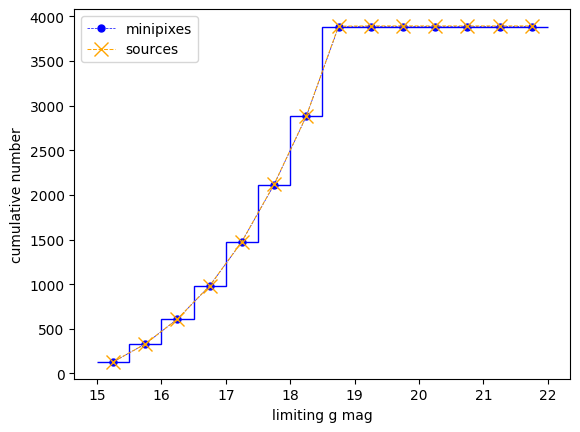

In [53]:
#minipix_cum_count = [len(i) for i in cumulative_unique_minipix_lists]
plt.plot(np.arange(15.25,22.25,0.5),cumulative_unique_minipix_count_per_bin,'o--',label="minipixes",alpha=1,markersize=5,lw=0.5,color="blue")
plt.stairs(cumulative_unique_minipix_count_per_bin, np.arange(15,22.5,0.5), baseline=None,color="blue")

cumulative_source_count_per_bin = np.cumsum(source_count_per_bin).tolist()
plt.plot(np.arange(15.25,22.25,0.5),cumulative_source_count_per_bin,'x--',label="sources",alpha=1,markersize=10,lw=0.75,color="orange")

plt.xlabel("limiting g mag")
plt.ylabel("cumulative number")
plt.legend()
plt.show()

Now try it out on the 1% of atlas.

Re-define my fuctions so that last part of looping through the mag bins is done in the main func:

In [34]:

def bin_mags(dframe,bin_col,bin_edges,meth,count=True):
    # establish data on which to bin
    data = dframe[bin_col]
    # define bin edges
    # bin with .....
    # - scipy
    if meth=="scipy.binstat":
        bins = scistat.binned_statistic(data, data, bins=bin_edges, statistic="count", range=(0, 1))
        bin_nums = bins.binnumber
        if count:
            counts = bins.statistic
    # - numpy
    elif meth=="numpy.dig":
        bin_nums = np.digitize(data,bin_edges,right=True)
        if count:
            counts = np.histogram(bin_nums,bins=len(bin_edges)-1)[0]
    # - or a method that is not supported
    else:
        print(f"method {meth} not supported")
    # make a column with bin number
    dframe['mag_bins'] = bin_nums
    # return dframe and, if specified, bin counts
    if count: 
        return(dframe,counts)
    else:
        return(dframe)
    

def lookup_minipix_idx(dframe,ra_col,dec_col,lookup):
    # Lookup tile IDs and local indices for all sources in dframe
    tanseg_ids, local_idxs = lookup.query_batch(dframe[ra_col], dframe[dec_col])
    # Add ID columns to dframe
    dframe["tanseg_id"] = tanseg_ids
    dframe["local_idx"] = local_idxs
    # return dframe
    return dframe

def bin_and_lookup_and_accum(dframe,bin_col,ra_col,dec_col,lookup):
    '''
    For a dataframe, 
        bin sources in magnitude, 
        look up tile/minipix ID for each source, 
        generate a list of "number of cumulative unique minipix" in each bin,
        return that list
    '''
    # - Make a copy of dframe
    dframe_copy = dframe.copy()
    # - Bin in g mag
    bin_edges = np.arange(15,22.5,0.5) # bin edges, right-most included
    bin_col = bin_col # column to bin on 
    meth = "scipy.binstat" # binning method
    dframe_copy,source_count_per_bin = bin_mags(dframe_copy,bin_col,bin_edges,meth,count=True)
    # - Look up tile/minipix idx
    dframe_copy = lookup_minipix_idx(dframe_copy,ra_col,dec_col,lookup)
    # - Loop through bins and get cumulative unique minipix count for each
    nbins = len(bin_edges)-1 # number of bins
    cumulative_unique_minipix_count_per_bin = [] # list of cumulative unique minipix count per bin
    cumulative_source_count_per_bin = np.cumsum(source_count_per_bin).tolist() # list of cumulative source count per bin
    for magbin in range(0,nbins):
        # - select sources in that bin and all brighter bins
        cum_bincat = dframe_copy[dframe_copy['mag_bins']<=(magbin+1)]
        # - generate the list of unique tile+minipix in all those bins & save the length
        cum_bin_unique_minipix = cum_bincat[['tanseg_id','local_idx']].drop_duplicates()
        cumulative_unique_minipix_count_per_bin.append(len(cum_bin_unique_minipix))
    return(cumulative_unique_minipix_count_per_bin, cumulative_source_count_per_bin)

In [8]:
# This cell takes a really long time to run!  Be warned

# define a TanSeg lookup & tiling scheme parameters
overlap_arcsec = SegmentationScheme.DEFAULT_OVERLAP_ARCSEC
tile_size_arcsec = SegmentationScheme.DEFAULT_TILE_SIZE_ARCSEC
pixel_scale_arcsec = SegmentationScheme.DEFAULT_PIXEL_SCALE
spacing_arcsec = tile_size_arcsec - overlap_arcsec
lookup = TanSegmentLookup(
    spacing_deg=spacing_arcsec/3600.0,
    pixel_scale_deg=pixel_scale_arcsec/3600.0,
    dec_min=-90.0,
    ra_min=0.0)

# create the delayed catalog and set up delayed dask computation:
delayed_atlas = atlas.catalog.to_delayed()
results = [dask.delayed(bin_and_lookup_and_accum)(p,"g","ra","dec",lookup) for p in delayed_atlas]
cum_minipix_counts = [r[0] for r in results]
cum_source_counts = [r[1] for r in results]

with Client(n_workers=4,memory_limit="20GiB",threads_per_worker=1) as client:
    # list of computed cumulative minipix counts per partition
    compute_cum_minipix_counts,compute_cum_source_counts = dask.compute(cum_minipix_counts,cum_source_counts)

/home/kmfas/hdps/.venv/lib/python3.14/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 18.40 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Stop and realize that I have not handled overlapping tiles...... the way I'm doing it now, the total number of unique minipix I count is an overcount because some of these minipix are actually overlapping...
Wait, is that true?  Does the minipix lookup always select the same certain tile over another where they overlap?  Wait, I think I'm fine..... 

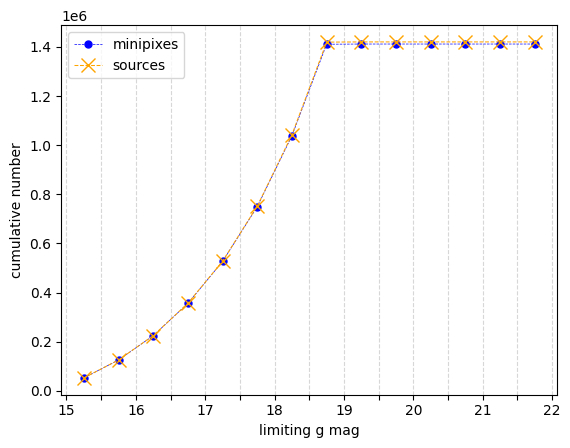

In [24]:
plt.grid(axis="x",alpha=0.5,ls="dashed")

# get tick labels
alternating_bin_edges = np.arange(15,23,1)
labels = [str(i) for i in alternating_bin_edges]
blanks = ["" for i in alternating_bin_edges]
tot_labels = [item for pair in zip(labels,blanks) for item in pair][:-1]


plt.xticks(list(np.arange(15,22.5,0.5)),tot_labels)

total_cum_minipix_count_per_bin = np.sum(compute_cum_minipix_counts, axis=0).tolist()
plt.plot(np.arange(15.25,22.25,0.5),total_cum_minipix_count_per_bin,'o--',label="minipixes",alpha=1,markersize=5,lw=0.5,color="blue")

total_cum_source_count_per_bin = np.sum(compute_cum_source_counts, axis=0).tolist()
plt.plot(np.arange(15.25,22.25,0.5),total_cum_source_count_per_bin,'x--',label="sources",alpha=1,markersize=10,lw=0.75,color="orange")

plt.xlabel("limiting g mag")
plt.ylabel("cumulative number")
plt.legend()
plt.show()

# Apply to an entire catalog; try PanSTARRS

In [3]:
# printed output from mminipix_per_mag.py 
cum_minipix_mag_bin_ps_f15 =  [5704409, 13192897, 23053943, 36604792, 55398781, 81358212, 117523266, 162507210, 201174556, 230877273, 270610502, 321384574, 368416395, 398087169]                                  
cum_source_mag_bin_ps_f15 =  [6086948.0, 14549317.0, 26369392.0, 43753945.0, 69733793.0, 109333561.0, 171352994.0, 259112458.0, 356792922.0, 463638538.0, 634104374.0, 913299370.0, 1264129632.0, 1581635337.0]


# counting ALL sources, not with a 15 mag upper cutoff
cum_minipix_mag_bin_ps_allmags =  [17799270, 25979690, 36840614, 51758192, 72345452, 100735430, 140121546, 188671666, 230215164, 262542081, 306189648, 362089410, 413744515, 446149584]
cum_source_mag_bin_ps_allmags =  [7065619.0, 16980276.0, 30988321.0, 51737861.0, 82698389.0, 129781839.0, 203081996.0, 306113309.0, 421758232.0, 549864806.0, 749684480.0, 1070530343.0, 1470282029.0, 1830177225.0]

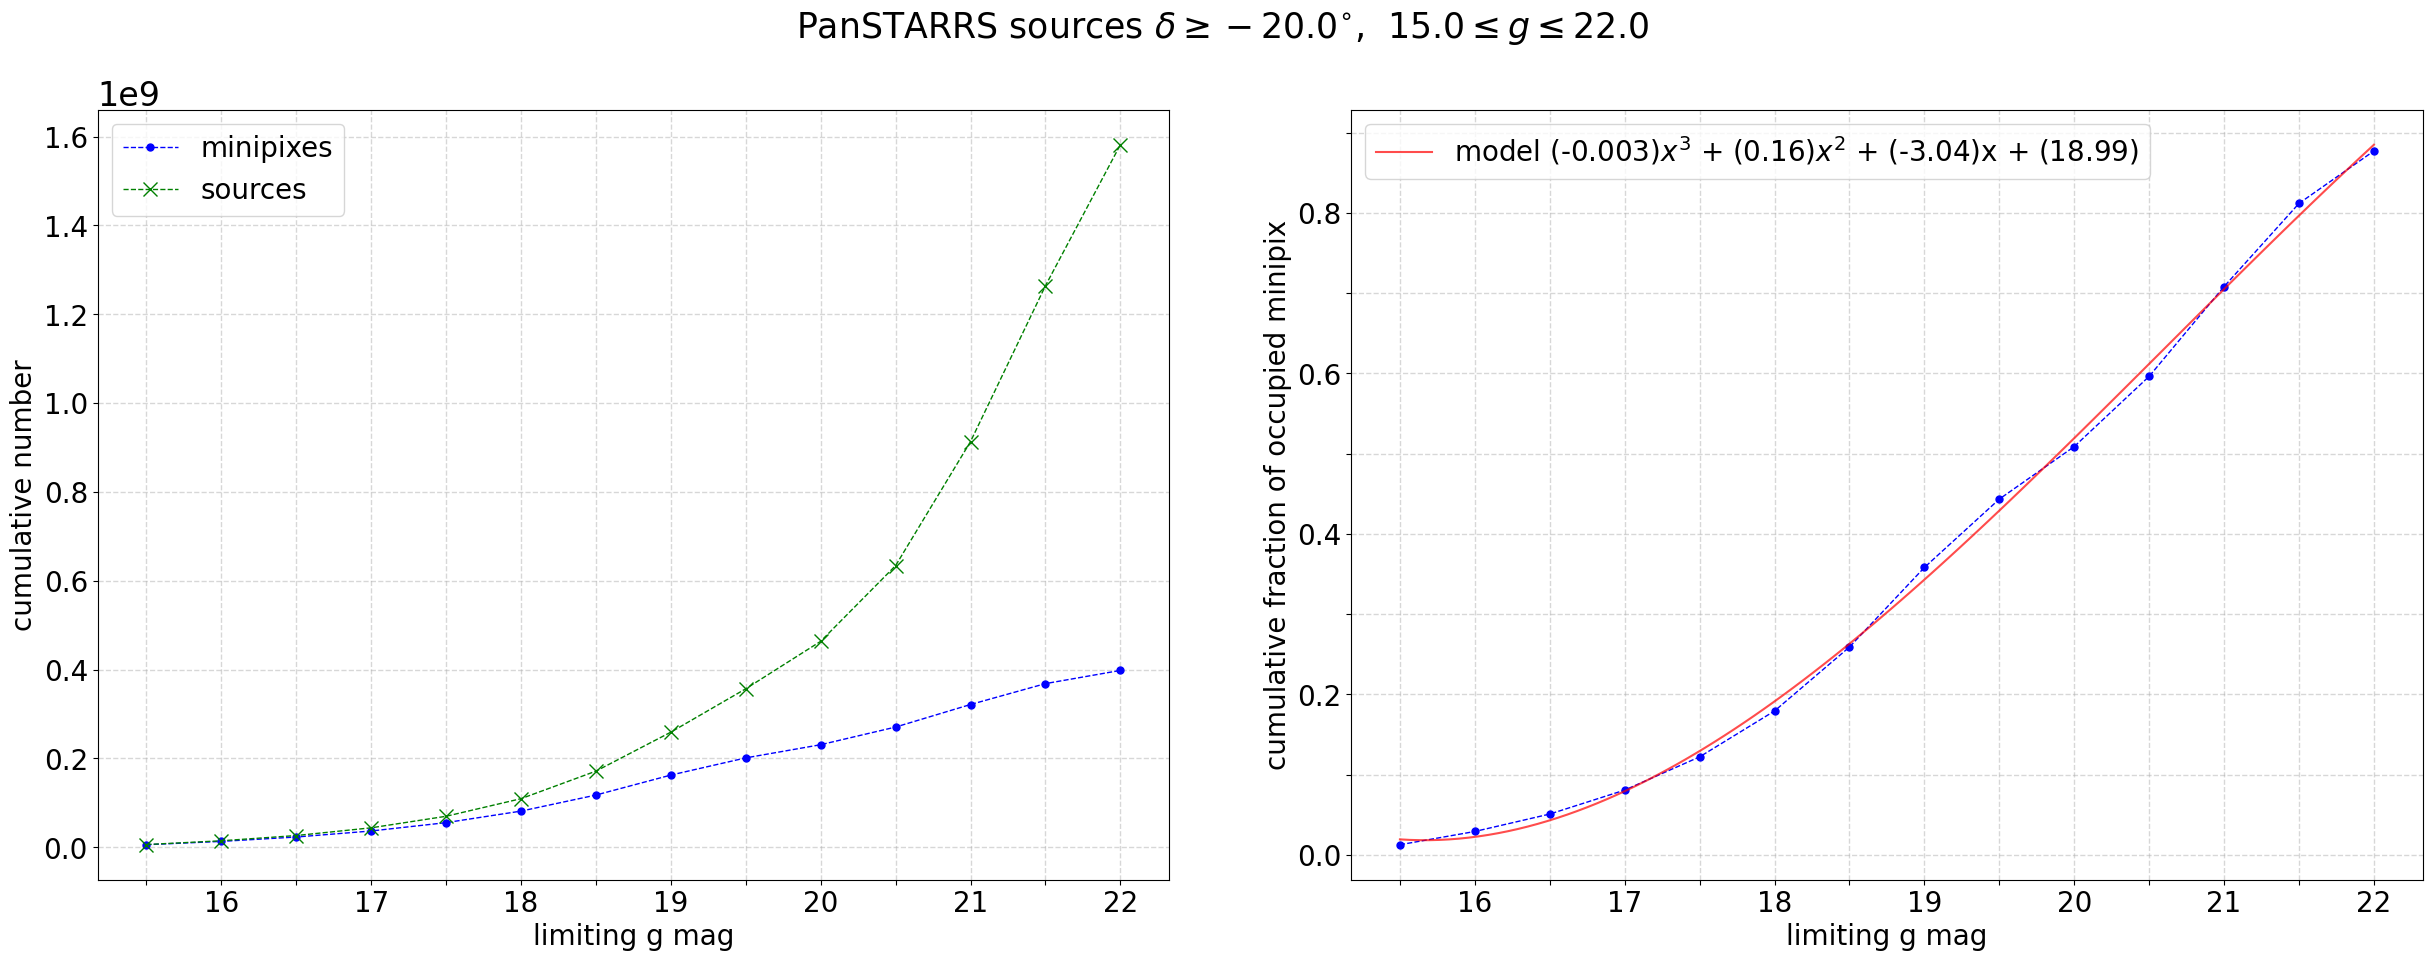

In [4]:
ls=20
ts=20

f,ax = plt.subplots(1,2,figsize=(30,10))
plt.subplots_adjust(wspace=0.17)
f.suptitle(r"PanSTARRS sources $\delta \geq -20.0^{\circ}$,  $15.0\leq g\leq 22.0$",fontsize=ls+5)

# get tick labels
alternating_bin_edges = np.arange(15,23,1)
labels = [str(i) for i in alternating_bin_edges]
blanks = ["" for i in alternating_bin_edges]
tot_labels = [item for pair in zip(labels,blanks) for item in pair][:-1]


xs = np.arange(15.5,22.5,0.5)

ax[0].grid(alpha=0.5,ls="dashed",lw=1) #axis="x"
ax[0].set_xticks([15.0]+list(xs),tot_labels)
ax[0].plot(xs,cum_minipix_mag_bin_ps_f15,'o--',label="minipixes",alpha=1,markersize=5,lw=1,color="blue")
ax[0].plot(xs,cum_source_mag_bin_ps_f15,'x--',label="sources",alpha=1,markersize=10,lw=1,color="green")
ax[0].set_xlabel("limiting g mag",fontsize=ls)
ax[0].set_ylabel("cumulative number",fontsize=ls)
ax[0].tick_params(labelsize=ts)
#plt.gca().yaxis.get_offset_text().set_fontsize(ts)
ax[0].yaxis.offsetText.set_fontsize(24)
ax[0].legend(fontsize=ls)



minipix_fracs = np.array(cum_minipix_mag_bin_ps_f15)/453810816

# fit with numpy
# https://scipy-lectures.org/intro/numpy/auto_examples/plot_polyfit.html
xn = np.arange(15.5,22.5,0.5)
yn = minipix_fracs
p = np.poly1d(np.polyfit(xn,yn,3))
t = np.linspace(15.5,22,100)

# Plot!
ax[1].grid(alpha=0.5,ls="dashed",lw=1) #axis="x"
ax[1].set_xticks([15.0]+list(xs),tot_labels)
ax[1].set_yticks(np.arange(0.0,1,0.1),["0.0","","0.2","","0.4","","0.6","","0.8",""])
ax[1].plot(xs,minipix_fracs,'o--',alpha=1,markersize=5,lw=1,color="blue")
ax[1].plot(t,p(t),'-',label=f"model ({p[3]:.3f})$x^3$ + ({p[2]:.2f})$x^2$ + ({p[1]:.2f})x + ({p[0]:.2f})",c="red",alpha=0.7) # numpy model
ax[1].set_xlabel("limiting g mag",fontsize=ls)
ax[1].set_ylabel("cumulative fraction of occupied minipix",fontsize=ls)
ax[1].tick_params(labelsize=ts)
ax[1].legend(fontsize=ls)

plt.show()
f.savefig("minipix_occupancy_panstarrs.png",dpi=400)

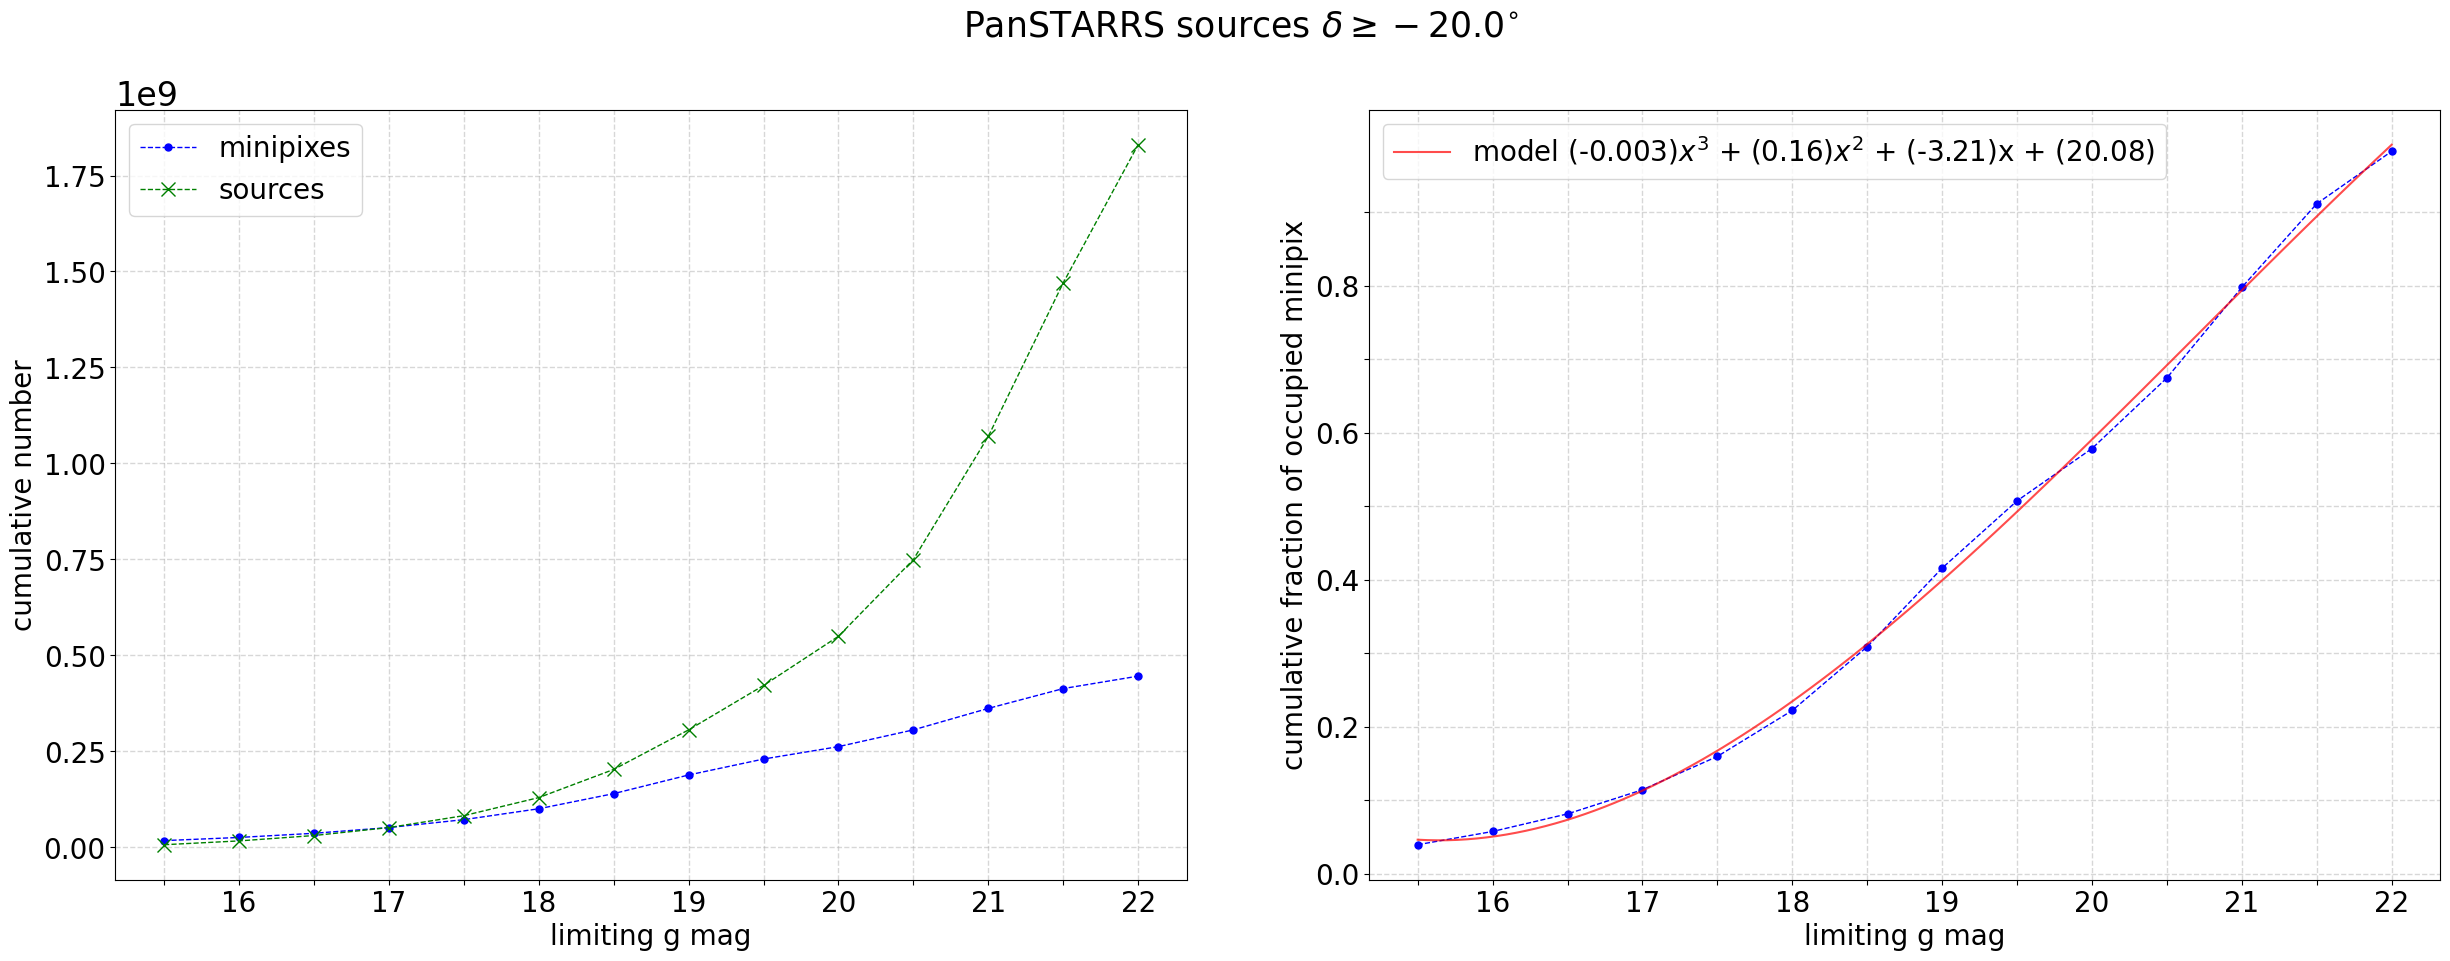

In [5]:
ls=20
ts=20

f,ax = plt.subplots(1,2,figsize=(30,10))
plt.subplots_adjust(wspace=0.17)
f.suptitle(r"PanSTARRS sources $\delta \geq -20.0^{\circ}$",fontsize=ls+5)

# get tick labels
alternating_bin_edges = np.arange(15,23,1)
labels = [str(i) for i in alternating_bin_edges]
blanks = ["" for i in alternating_bin_edges]
tot_labels = [item for pair in zip(labels,blanks) for item in pair][:-1]


xs = np.arange(15.5,22.5,0.5)

ax[0].grid(alpha=0.5,ls="dashed",lw=1) #axis="x"
ax[0].set_xticks([15.0]+list(xs),tot_labels)
ax[0].plot(xs,cum_minipix_mag_bin_ps_allmags,'o--',label="minipixes",alpha=1,markersize=5,lw=1,color="blue")
ax[0].plot(xs,cum_source_mag_bin_ps_allmags,'x--',label="sources",alpha=1,markersize=10,lw=1,color="green")
ax[0].set_xlabel("limiting g mag",fontsize=ls)
ax[0].set_ylabel("cumulative number",fontsize=ls)
ax[0].tick_params(labelsize=ts)
#plt.gca().yaxis.get_offset_text().set_fontsize(ts)
ax[0].yaxis.offsetText.set_fontsize(24)
ax[0].legend(fontsize=ls)



minipix_fracs = np.array(cum_minipix_mag_bin_ps_allmags)/453810816

# fit with numpy
# https://scipy-lectures.org/intro/numpy/auto_examples/plot_polyfit.html
xn = np.arange(15.5,22.5,0.5)
yn = minipix_fracs
p = np.poly1d(np.polyfit(xn,yn,3))
t = np.linspace(15.5,22,100)

# Plot!
ax[1].grid(alpha=0.5,ls="dashed",lw=1) #axis="x"
ax[1].set_xticks([15.0]+list(xs),tot_labels)
ax[1].set_yticks(np.arange(0.0,1,0.1),["0.0","","0.2","","0.4","","0.6","","0.8",""])
ax[1].plot(xs,minipix_fracs,'o--',alpha=1,markersize=5,lw=1,color="blue")
ax[1].plot(t,p(t),'-',label=f"model ({p[3]:.3f})$x^3$ + ({p[2]:.2f})$x^2$ + ({p[1]:.2f})x + ({p[0]:.2f})",c="red",alpha=0.7) # numpy model
ax[1].set_xlabel("limiting g mag",fontsize=ls)
ax[1].set_ylabel("cumulative fraction of occupied minipix",fontsize=ls)
ax[1].tick_params(labelsize=ts)
ax[1].legend(fontsize=ls)

plt.show()
f.savefig("minipix_occupancy_panstarrs.png",dpi=400)

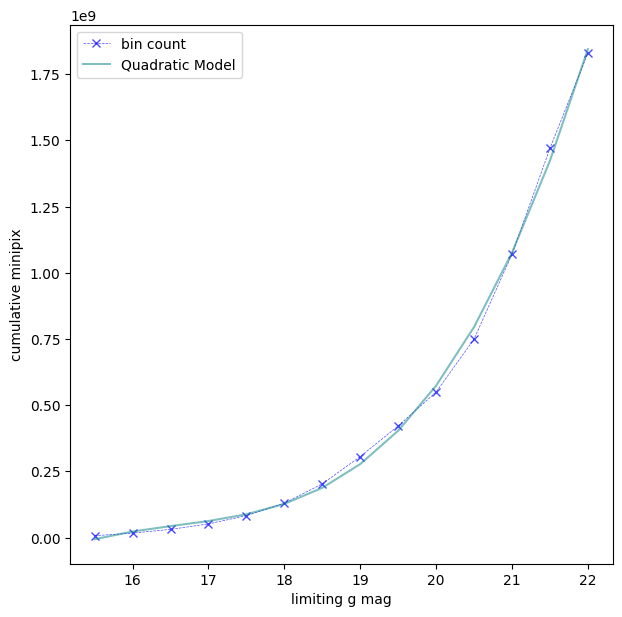

In [22]:
def quadratic_func(x,a,b,c,d):
    return(((x**3)*a)+((x**2)*b)+((x)*c)+(d))

# Fit!
x = np.arange(15.5,22.5,0.5)
y = cum_source_mag_bin_ps
best_vals, covar = curve_fit(quadratic_func, x, y)

# Plot!
f,ax = plt.subplots(1,1,sharex=True,figsize=(7,7))#,sharey=True)
plt.subplots_adjust(hspace=0)
#f.suptitle(r"Argus $b$,$\rho$ to SDSS $g$,$r$ as a function of Argus color ($b-\rho$)")
ax.plot(x,cum_source_mag_bin_ps,"x--",label="bin count",alpha=0.7,color="blue",lw=0.5)
ax.plot(x,quadratic_func(x,best_vals[0],best_vals[1],best_vals[2],best_vals[3]),label="Quadratic Model",alpha=0.5,c="teal")
ax.set_xlabel("limiting g mag")
ax.set_ylabel("cumulative minipix")
plt.legend()
plt.show()

## Trying to get total minipix count across the sky

I will get the coordinates of every tile+minipix, then get a list of unique coordinates, and that is how many unique minipix there are in the sky (not counting overlapping duplicates)

In [115]:
overlap_arcsec = SegmentationScheme.DEFAULT_OVERLAP_ARCSEC
tile_size_arcsec = SegmentationScheme.DEFAULT_TILE_SIZE_ARCSEC
pixel_scale_arcsec = SegmentationScheme.DEFAULT_PIXEL_SCALE
spacing_arcsec = tile_size_arcsec - overlap_arcsec
lookup = TanSegmentLookup(
    spacing_deg=spacing_arcsec/3600.0,
    pixel_scale_deg=pixel_scale_arcsec/3600.0,
    dec_min=-90.0,
    ra_min=0.0)

In [2]:
scheme = SegmentationScheme.all_sky()

Loading SegmentationScheme from cache: /home/kmfas/.hdps/skymap_cache/segscheme_v2_tile1800p0_overlap28p125_ps0p87890625_ra0-360_dec-90-90.fits
Loaded 170448 tiles from cache


In [94]:
tile_ids = np.unique([i['tile_id'] for i in scheme.tiles])
local_ids = np.arange(0,64*64,1)
minipix_ras =[]
minipix_decx = []
minipix_coords = set() #[]
minipix_coords_above_n20 = set()

for tile_id,iter in zip(tile_ids,np.arange(0,len(tile_ids))):
    if iter%1000==0: print(iter)
    #id_sets = [[tile_id,local_id] for local_id in local_ids]
    tile_minipix_ras,tile_minipix_decs = composite_id_to_radec(np.repeat(tile_id,len(local_ids)),local_ids,spacing_deg=spacing_arcsec/3600.0,pixel_scale_deg=pixel_scale_arcsec/3600.0,dec_min=-90.0,ra_min=0.0)
    for ra,dec in zip(tile_minipix_ras,tile_minipix_decs):
        minipix_coords.add(tuple([ra,dec])) #scheme.tile_id_to_radec(id_set[0],id_set[1]))
        if dec>=-20:
            minipix_coords_above_n20.add(tuple([ra,dec]))

0
1000
2000
3000
4000
5000
6000
7000
8000
9000
10000
11000
12000
13000
14000
15000
16000
17000
18000
19000
20000
21000
22000
23000
24000
25000
26000
27000
28000
29000
30000
31000
32000
33000
34000
35000
36000
37000
38000
39000
40000
41000
42000
43000
44000
45000
46000
47000
48000
49000
50000
51000
52000
53000
54000
55000
56000
57000
58000
59000
60000
61000
62000
63000
64000
65000
66000
67000
68000
69000
70000
71000
72000
73000
74000
75000
76000
77000
78000
79000
80000
81000
82000
83000
84000
85000
86000
87000
88000
89000
90000
91000
92000
93000
94000
95000
96000
97000
98000
99000
100000
101000
102000
103000
104000
105000
106000
107000
108000
109000
110000
111000
112000
113000
114000
115000
116000
117000
118000
119000
120000
121000
122000
123000
124000
125000
126000
127000
128000
129000
130000
131000
132000
133000
134000
135000
136000
137000
138000
139000
140000
141000
142000
143000
144000
145000
146000
147000
148000
149000
150000
151000
152000
153000
154000
155000
156000
157000
158000


In [ ]:
print(f"{len(minipix_coords_above_n20)/len(minipix_coords)}% of minipix are north of Dec=-20deg")

(698155008, 468469760)

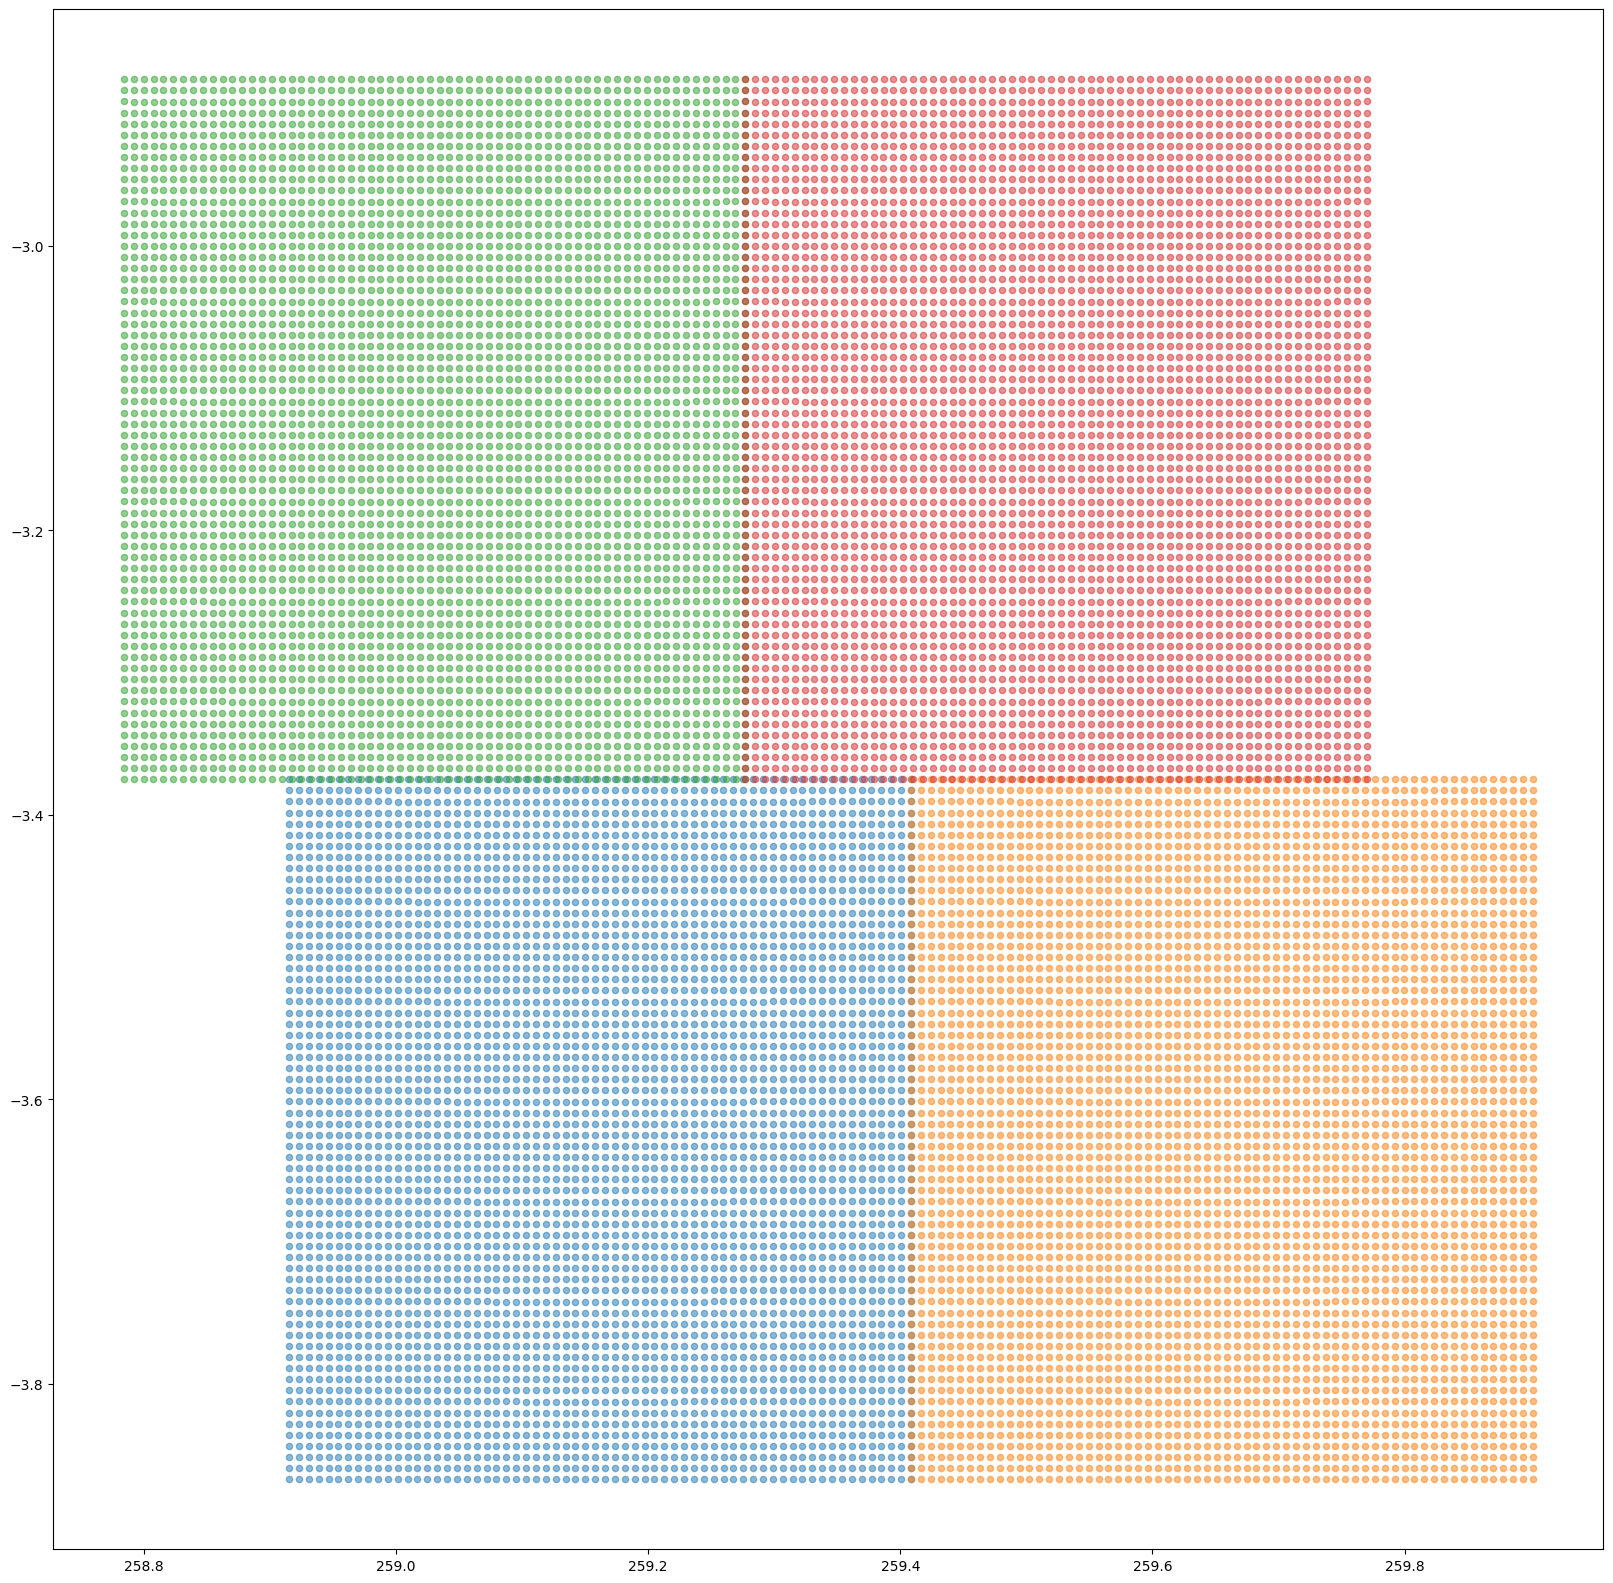

In [ ]:
# show that minipix overlap
# query a tile at this coordinate: lookup.query(259,-3.2) = 253965,1443
tilez = [i['tile_id'] for i in scheme.tiles[80000:80002]] + [253965,253966]
local_ids = np.arange(0,64*64,1)
plt.figure(figsize=(20,20))
for til in tilez:

    tile_minipix_ras,tile_minipix_decs = composite_id_to_radec(np.repeat(til,len(local_ids)),local_ids,spacing_deg=spacing_arcsec/3600.0,pixel_scale_deg=pixel_scale_arcsec/3600.0,dec_min=-90.0,ra_min=0.0)
    plt.scatter(tile_minipix_ras,tile_minipix_decs,s=20,alpha=0.5)
plt.show()

In [161]:
# very rough overlap subtraction:

# get dec band at dec=-20deg:
from hdps.skymap import dec_band_from_tanseg_id
tid,mid = lookup.query(259,-20)
min_dec_band = dec_band_from_tanseg_id(tid)

# get dec bands
dec_bands = np.array([i['dec_band'] for i in scheme.tiles])
dec_bands = dec_bands[dec_bands>=min_dec_band] # to only get dec bands above -20deg

# set up total minipix counts
#tot_minipix_duplicates = len(scheme.tiles)*4096 # all-sky, not removing minipix for overlapping
#tot_minipix = len(scheme.tiles)*4096 # all-sky, post removing overlapping minipix
tot_minipix_duplicates = len(minipix_coords_above_n20) # above dec=-20, not removing minipix for overlapping
tot_minipix = len(minipix_coords_above_n20) # above dec=-20, post removing overlapping minipix

# iterate through dec bands and subtract overlapping minipix:
for dec_band in np.unique(dec_bands):
    ntiles = len(dec_bands[dec_bands==dec_band])
    tot_minipix-=((ntiles*64)*2)
    
tot_minipix_duplicates,tot_minipix # note that the tot_minipix = (len(tile_ids)*(len(local_ids)-(64*2)))

(468469760, 453810816)

## Fit model to minipix occupancy fraction in each magbin:

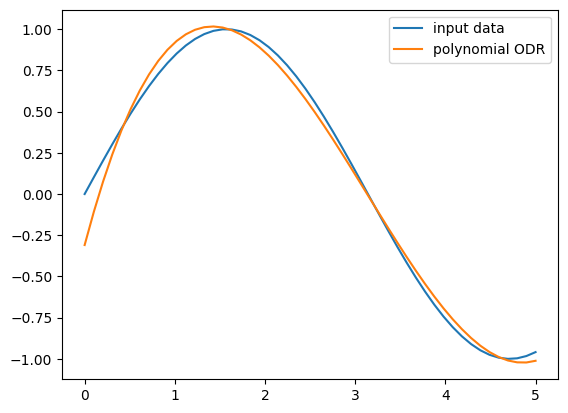

In [ ]:
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.odr.polynomial.html
from scipy import odr

x = np.linspace(0.0, 5.0)
y = np.sin(x)

poly_model_3rd = odr.polynomial(3)  # using third order polynomial model
data = odr.Data(x, y)

odr_obj = odr.ODR(data, poly_model_3rd)
output = odr_obj.run()  # running ODR fitting
poly = np.poly1d(output.beta[::-1])
poly_y = poly(x)
plt.plot(x, y, label="input data")
plt.plot(x, poly_y, label="polynomial ODR")
plt.legend()
plt.show()


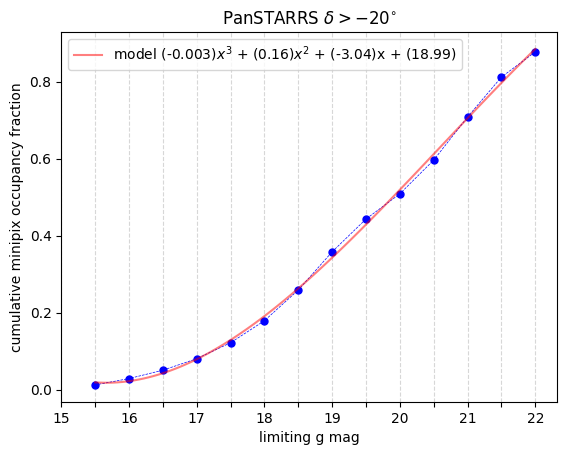

In [ ]:
cum_minipix_mag_bin_ps =  [5704409, 13192897, 23053943, 36604792, 55398781, 81358212, 117523266, 162507210, 201174556, 230877273, 270610502, 321384574, 368416395, 398087169]                                  
minipix_fracs = np.array(cum_minipix_mag_bin_ps)/453810816


plt.title(r"PanSTARRS $\delta > -20^{\circ}$")
plt.grid(axis="x",alpha=0.5,ls="dashed")

# get tick labels
alternating_bin_edges = np.arange(15,23,1)
labels = [str(i) for i in alternating_bin_edges]
blanks = ["" for i in alternating_bin_edges]
tot_labels = [item for pair in zip(labels,blanks) for item in pair][:-1]


# fit with scipy
def quadratic_func(x,a,b,c,d):
    return((a)+((x**3)*b)+((x**2)*c)+((x)*d))
# Fit!
x = np.arange(15.5,22.5,0.5)
y = minipix_fracs
best_vals, covar = curve_fit(quadratic_func, x, y)


# fit with numpy
# https://scipy-lectures.org/intro/numpy/auto_examples/plot_polyfit.html
xn = np.arange(15.5,22.5,0.5)
yn = minipix_fracs
p = np.poly1d(np.polyfit(xn,yn,3))
t = np.linspace(15.5,22,100)


# Plot!
#plt.plot(x,quadratic_func(x,best_vals[0],best_vals[1],best_vals[2],best_vals[3]),label="scipy Model",alpha=0.5,c="teal",ls="dashed")
plt.plot(np.arange(15.5,22.5,0.5),minipix_fracs,'o--',alpha=1,markersize=5,lw=0.5,color="blue")
plt.plot(t,p(t),'-',label=f"model ({p[3]:.3f})$x^3$ + ({p[2]:.2f})$x^2$ + ({p[1]:.2f})x + ({p[0]:.2f})",c="red",alpha=0.5) # numpy model

plt.xticks(list(np.arange(15,22.5,0.5)),tot_labels)

plt.xlabel("limiting g mag")
plt.ylabel("cumulative minipix occupancy fraction")
plt.legend()
plt.show()

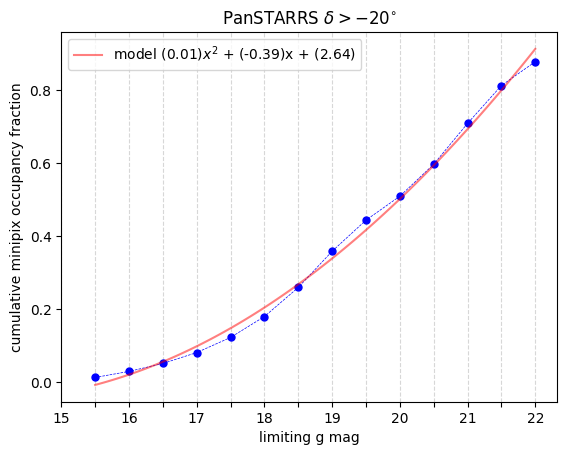

In [44]:
cum_minipix_mag_bin_ps =  [5704409, 13192897, 23053943, 36604792, 55398781, 81358212, 117523266, 162507210, 201174556, 230877273, 270610502, 321384574, 368416395,
 398087169]                                  
minipix_fracs = np.array(cum_minipix_mag_bin_ps)/453810816


plt.title(r"PanSTARRS $\delta > -20^{\circ}$")
plt.grid(axis="x",alpha=0.5,ls="dashed")

# get tick labels
alternating_bin_edges = np.arange(15,23,1)
labels = [str(i) for i in alternating_bin_edges]
blanks = ["" for i in alternating_bin_edges]
tot_labels = [item for pair in zip(labels,blanks) for item in pair][:-1]


# fit with numpy
# https://scipy-lectures.org/intro/numpy/auto_examples/plot_polyfit.html
xn = np.arange(15.5,22.5,0.5)
yn = minipix_fracs
p = np.poly1d(np.polyfit(xn,yn,2))
t = np.linspace(15.5,22,100)


# Plot!
#plt.plot(x,quadratic_func(x,best_vals[0],best_vals[1],best_vals[2],best_vals[3]),label="scipy Model",alpha=0.5,c="teal",ls="dashed")
plt.plot(np.arange(15.5,22.5,0.5),minipix_fracs,'o--',alpha=1,markersize=5,lw=0.5,color="blue")
plt.plot(t,p(t),'-',label=f"model ({p[2]:.2f})$x^2$ + ({p[1]:.2f})x + ({p[0]:.2f})",c="red",alpha=0.5) # numpy model

plt.xticks(list(np.arange(15,22.5,0.5)),tot_labels)

plt.xlabel("limiting g mag")
plt.ylabel("cumulative minipix occupancy fraction")
plt.legend()
plt.show()

## on ATLAS full:

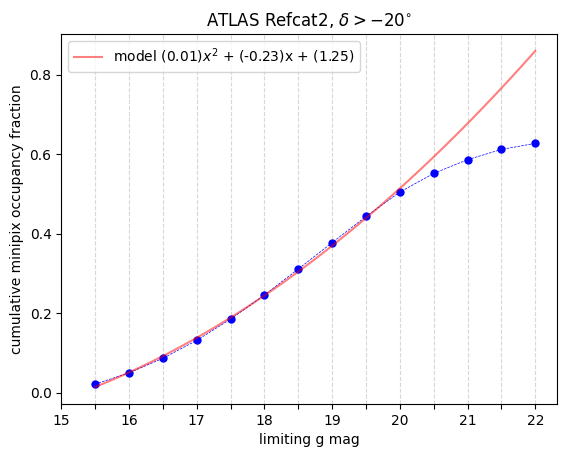

In [214]:
total_cum_minipix_per_bin_atlas =  [9586464, 22416552, 39028053, 59497409, 83775721, 111314086, 140982510, 171102796, 200953950, 228829409, 250177820, 265819028, 277510787, 284459732]
total_cum_source_per_bin_atlas =  [10020328.0, 24185331.0, 43903155.0, 70839961.0, 107463588.0, 157123184.0, 225119246.0, 318217314.0, 443103145.0, 603079383.0, 749981266.0, 852532644.0, 919165718.0, 957531892.0]

minipix_fracs = np.array(total_cum_minipix_per_bin_atlas)/453810816


plt.title(r"ATLAS Refcat2, $\delta > -20^{\circ}$")
plt.grid(axis="x",alpha=0.5,ls="dashed")

# get tick labels
alternating_bin_edges = np.arange(15,23,1)
labels = [str(i) for i in alternating_bin_edges]
blanks = ["" for i in alternating_bin_edges]
tot_labels = [item for pair in zip(labels,blanks) for item in pair][:-1]


# fit with numpy
# https://scipy-lectures.org/intro/numpy/auto_examples/plot_polyfit.html
xn = np.arange(15.5,22.5,0.5)[:-4]
yn = minipix_fracs[:-4]
p = np.poly1d(np.polyfit(xn,yn,2))
t = np.linspace(15.5,22,100)


# Plot!
#plt.plot(x,quadratic_func(x,best_vals[0],best_vals[1],best_vals[2],best_vals[3]),label="scipy Model",alpha=0.5,c="teal",ls="dashed")
plt.plot(np.arange(15.5,22.5,0.5),minipix_fracs,'o--',alpha=1,markersize=5,lw=0.5,color="blue")
plt.plot(t,p(t),'-',label=f"model ({p[2]:.2f})$x^2$ + ({p[1]:.2f})x + ({p[0]:.2f})",c="red",alpha=0.5) # numpy model ({p[3]:.3f})$x^3$ +

plt.xticks(list(np.arange(15,22.5,0.5)),tot_labels)

plt.xlabel("limiting g mag")
plt.ylabel("cumulative minipix occupancy fraction")
plt.legend()
plt.show()

# .Estimating mag cutoff (and #sources, minipix) for.......

4 situations: 

- (1) Nightly storage budget = 6400GB
    - (1a) 60s cadence
    - (1b) 1s cadence
- (2) Nightly storage budget = 22000GB
    - (2a) 60s cadence
    - (2b) 1s cadence

Note that this estimation, like the minipix occupancy estimation, assumes that all sources are point sources and only appear in one minipix.

Each full-frame image covers 8,000 deg^2.  

Each tile covers 0.5*0.5 = 0.25 deg^2, so within one full-frame image there are about (8000/((0.5)**2))=~32000 tiles not counting overlap, 8000/((0.5-(28.1/60/60))**2)=~33000 counting it.  

That is 33000*(64*60)=~130,000,000 minipix per image.

We have a fraction of the total minipix that would contain sources, as a function of limiting mag.  

at 21.5 mags limiting mag in g, that fraction is 368416390/453810816 = 0.81

so, we could argue that about 0.81*130,000,000 = 105,537,658 minipix that are active, per image.  

So let's do a dry run and establish some globals:

In [2]:
# global params:
minipix_b = 2135 # size of record files associated single minipix [B]
nminipix_north_n20 = 453_810_816 # number of minipix north of -20deg declination 

# image and minipix sizes
image_fov_deg = 8_000 # degrees squared
image_fov_arcsec = image_fov_deg * 3600.0 * 3600.0              # image fov    = 103680000000.0 arcsec squared
overlap_arcsec = SegmentationScheme.DEFAULT_OVERLAP_ARCSEC      # tile overlap = 28.125 arcsec
tile_size_arcsec = SegmentationScheme.DEFAULT_TILE_SIZE_ARCSEC  # tile size    = 1800.0 arcsec
pixel_scale_arcsec = SegmentationScheme.DEFAULT_PIXEL_SCALE     # pixel scale  = 0.87890625 arcsec
minipix_size_arcsec = overlap_arcsec                            # minipix size = 28.125 arcsec 
minipix_fov_arcsec = minipix_size_arcsec**2                     # minipix fov  = 791.015625 arcsec squared
nminipix_per_image = image_fov_arcsec/minipix_fov_arcsec
print(f"{nminipix_per_image} minipix per image")

# night timings
night_hr = 10 # #hr dark time per night, on average 
night_s = night_hr*60*60 # #sec per night
n_im_60s = night_s/60 # #images per night at 60s cadence
n_im_1s = night_s # #images per night at 1sec cadence
print(f"{n_im_60s} images per night at 60s, {n_im_1s} at 1s cadences")

131072000.0 minipix per image
600.0 images per night at 60s, 36000 at 1s cadences


In [3]:
night_size_60 = (nminipix_per_image*n_im_60s)*minipix_b # how much bytes if save all minipix in each image for one night, at 60sec cadence
6400/(night_size_60/1024/1024/1024) * (nminipix_per_image)

5364518.090241998

In [4]:
sky_fov_arcsec = 27_681*3600*3600 # square arcsec of sky above -20dec
sky_fov_arcsec/minipix_fov_arcsec

453525504.0

In [5]:
# dry run at limiting mag = 21.5 

# get fraction of active minipix active for limmag
nminipix_at_21_5_limmag =  368_416_395   # a test value from PanSTARRS limiting mag 21.5 (cum minipix) so i can work out the math
#tot_cat_size_b = nminipix_at_21_5_limmag * minipix_b
#tot_cat_size_gb = tot_cat_size_b/1024/1024/1024 # total minipix catalog size if we save only one image cutout of each minipix. 
minipix_frac_21_5_limmag = nminipix_at_21_5_limmag/nminipix_north_n20
print(f"{minipix_frac_21_5_limmag*100:.0f}% of minipix active at limiting mag of 21.5") 

# get active minipix in a single image
nactiveminipix_per_image_21_5_limmag = nminipix_per_image * minipix_frac_21_5_limmag
print(f"~{int(nactiveminipix_per_image_21_5_limmag)} active minipix per image at limiting mag = 21.5")

# get size of minipixes accumulated in single image
minipix_image_size_b_21_5 = nactiveminipix_per_image_21_5_limmag * minipix_b # bytes accumulated from minipix from a single image at limmag 201.5
night_size_60s_gb = (n_im_60s * minipix_image_size_b_21_5)/1024/1024/1024
print(f"{night_size_60s_gb} GB accumulated per night at 60s cadence")

81% of minipix active at limiting mag of 21.5
~106407939 active minipix per image at limiting mag = 21.5
126947.24848342482 GB accumulated per night at 60s cadence


In [ ]:
# how many minipix come off the cameras each night?  
# if each ratchet accumulates 15min of images, that's 900 sec, which is either 15 (60sec) or 900 (1sec) images.  
ratchet_length_min = 15 # minutes
ratchet_length_sec = ratchet_length_min*60
(nminipix_per_image*(ratchet_length_sec/60)*minipix_b)

1966080000.0

In [22]:
from math import sqrt, acos, floor, sin

# Function to return area of intersection
def intersectionArea(X1, Y1, R1, X2, Y2, R2) :

    Pi = 3.14
    
    # Calculate the euclidean distance
    # between the two points
    d = sqrt(((X2 - X1) * (X2 - X1)) + ((Y2 - Y1) * (Y2 - Y1)))

    if (d > R1 + R2) :
        ans = 0

    elif (d <= (R1 - R2) and R1 >= R2) :
        ans = floor(Pi * R2 * R2)

    elif (d <= (R2 - R1) and R2 >= R1) :
        ans = floor(Pi * R1 * R1)

    else :
        alpha = acos(((R1 * R1) + (d * d) - (R2 * R2)) / (2 * R1 * d)) * 2
        beta = acos(((R2 * R2) + (d * d) - (R1 * R1)) / (2 * R2 * d)) * 2;        
        a1 = (0.5 * beta * R2 * R2 ) - (0.5 * R2 * R2 * sin(beta))
        a2 = (0.5 * alpha * R1 * R1) - (0.5 * R1 * R1 * sin(alpha))
        ans = floor(a1 + a2)

    return ans


X1 = 100; Y1 = 10; R1 = (8000/np.pi)**(1/2) 
X2 = 103.75; Y2 = 10; R2 = (8000/np.pi)**(1/2) 

    # Function Call
((8000-intersectionArea(X1, Y1, R1, X2, Y2, R2))/8000)*nminipix_per_image
    

6209536.0

In [26]:
(((nminipix_per_image)+(6209536*((n_im_60s/15)-1))))#*minipix_b)/1024/1024/1024

373243904.0

In [18]:
nightly_vol_gb = ((nminipix_per_image*n_im_60s)*minipix_b)/1024/1024/1024
(6400/nightly_vol_gb)*nminipix_north_n20

18573580.413661826

In [11]:
(8000/np.pi)**(1/2) 

50.4626504404032

In [10]:
(360/(24*60))*ratchet_length_min

3.75

In [6]:
# If I had a max budget, how would I figure out how many minipix I can save?
# Use the model.  
#cum_minipix_mag_bin_ps =  [5704409, 13192897, 23053943, 36604792, 55398781, 81358212, 117523266, 162507210, 201174556, 230877273, 270610502, 321384574, 368416395, 398087169]                                  
cum_minipix_mag_bin_ps =  [17799270, 25979690, 36840614, 51758192, 72345452, 100735430, 140121546, 188671666, 230215164, 262542081, 306189648, 362089410, 413744515, 446149584]
cum_source_mag_bin_ps =  [7065619.0, 16980276.0, 30988321.0, 51737861.0, 82698389.0, 129781839.0, 203081996.0, 306113309.0, 421758232.0, 549864806.0, 749684480.0, 1070530343.0, 1470282029.0, 1830177225.0]

minipix_fracs = np.array(cum_minipix_mag_bin_ps)/453810816
limmag_points = np.arange(15.5,22.5,0.5)
xn = limmag_points
yn = minipix_fracs
minipix_frac_model = np.poly1d(np.polyfit(xn,yn,2))
minipix_frac_model(21.5)


#cum_source_mag_bin_ps =  [6086948.0, 14549317.0, 26369392.0, 43753945.0, 69733793.0, 109333561.0, 171352994.0, 259112458.0, 356792922.0, 463638538.0, 634104374.0, 913299370.0, 1264129632.0, 1581635337.0]
xn_src = np.arange(15.5,22.5,0.5)
yn_src = cum_source_mag_bin_ps
src_per_limmag = np.poly1d(np.polyfit(xn_src,yn_src,3))


In [10]:
src_per_limmag(21)

np.float64(1076129760.9341507)

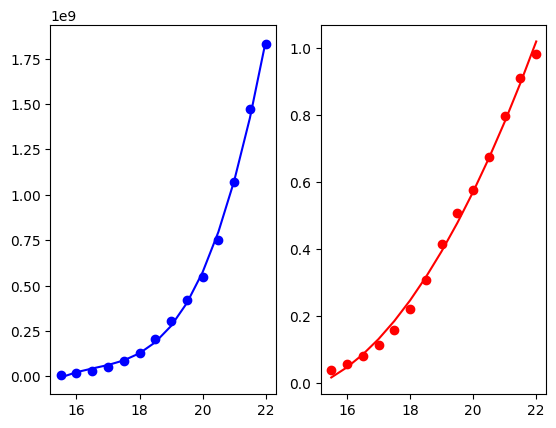

In [13]:
f,ax = plt.subplots(1,2)
ax[0].scatter(xn_src,yn_src,c="blue")
ax[0].plot(xn_src,src_per_limmag(xn_src),c="blue")

ax[1].scatter(xn,yn,c="red")
ax[1].plot(xn,minipix_frac_model(xn),c="red")

plt.show()

In [16]:
# for a given minipix fraction, get the corresponding limiting mag 
from scipy.optimize import fsolve  

target_minipix_frac = 0.1
equ_to_solve = lambda x: minipix_frac_model(x) - target_minipix_frac
init_guess = 15
var_x = fsolve(equ_to_solve,init_guess)
print(target_minipix_frac,var_x[0],src_per_limmag(var_x[0]))

0.1 16.657909808151082 49132344.58106232


In [85]:
def minipix_capabilities(night_budget_gb,cadence_sec):
    # minpix globals
    minipix_b = 2135 # size of record files associated single minipix [B]
    nminipix_north_n20 = 453810816 # number of minipix north of -20deg declination 

    # image and minipix sizes
    image_fov_deg = 8_000 # degrees squared
    image_fov_arcsec = image_fov_deg * 3600.0 * 3600.0              # image fov    = 103680000000.0 arcsec squared
    overlap_arcsec = SegmentationScheme.DEFAULT_OVERLAP_ARCSEC      # tile overlap = 28.125 arcsec
    minipix_size_arcsec = overlap_arcsec/2                            # minipix size = 28.125 arcsec 
    minipix_fov_arcsec = minipix_size_arcsec**2                     # minipix fov  = 791.015625 arcsec squared
    nminipix_per_image = image_fov_arcsec/minipix_fov_arcsec        # minipix per image = 131072000

    # night budget
    night_budget_b = night_budget_gb * 1024*1024*1024

    # n_images per night
    night_hr = 10 # #hr dark time per night, on average 
    night_s = night_hr*60*60 # #sec per night
    nim_per_night = night_s/cadence_sec

    # 
    image_budget_b = night_budget_b/nim_per_night # size each image can have in bytes
    minipix_budget_per_image = image_budget_b/minipix_b # number of minipix that can be activated in each image
    minipix_budget_frac_per_image = minipix_budget_per_image/nminipix_per_image # fraction of minipix per image that can be active -> fraction of all minipix that can be active
    minipix_budget_n20 = minipix_budget_frac_per_image * nminipix_north_n20

    return(minipix_budget_n20,minipix_budget_frac_per_image)


In [86]:
minipix_capabilities(6400,60),minipix_capabilities(6400,1),minipix_capabilities(22000,60),minipix_capabilities(22000,1)

((4643395.103415457, 0.010232006245121),
 (77389.9183902576, 0.0001705334374186833),
 (15961670.667990632, 0.03517252146760343),
 (266027.8444665106, 0.000586208691126724))

| Nightly Storage Budget | Cadence| # Minipix |
|----|-----|-----|
| 6400 GB | 60 s | 18,573,500 |
|  | 1 s | 309,600 |
| 22000 GB | 60 s | 63,846,700 |
| | 1 s | 1,064,100 |

## ..Nightly storage budget = 6400GB

### ...60s cadence

In [ ]:
night_budget_gb = 6400 # max storage capacity [GB]


In [ ]:
image_budget_b_60s = night_budget_b/n_im_60s # the size each image can have, given max nightly storage, at 60s cadence all night
minipix_budget_60s = image_budget_b_60s/minipix_b # the number of minipix that we can activate in each image given max nightly storage, at 60s cadence 
minipix_frac_60s = minipix_budget_60s/nminipix_per_image # the fraction of minpix we can activate to stay within the budget
int(minipix_frac_60s * nminipix_north_n20)

18573580

### ...1s cadence

In [ ]:
image_budget_b_1s = night_budget_b/n_im_1s # the size each image can have, given max nightly storage, at 60s cadence all night
minipix_budget_1s = image_budget_b_1s/minipix_b # the number of minipix that we can activate in each image given max nightly storage, at 60s cadence 
minipix_frac_1s = minipix_budget_1s/nminipix_per_image # the fraction of minpix we can activate to stay within the budget
int(minipix_frac_1s * nminipix_north_n20)

309559

# .Storage Number Check

For one night:
- start with X exposures at one ratchet pointing 
- then,  

In [3]:
tot_epochs_per_pos_60 = 142000
tot_epochs_per_pos_60/5/365/15

5.187214611872147

In [ ]:
(15*(360/24/60))

3.75

In [ ]:
night_hr = 10
pointings_per_night = (night_hr*60)/15
pointings_per_night*365

40.0

In [132]:
n_ratchets_to_move_fov_radius_deg*2

26.91341356821504

In [135]:
6400/(((2135*400))/1024/1024/1024)

8046777.135362998

In [134]:
24*15

360

In [133]:
fov_radius_deg = (8000/np.pi)**(1/2)
n_ratchets_to_move_fov_radius_deg = (fov_radius_deg/3.75)
n_epochs = n_ratchets_to_move_fov_radius_deg*15
n_epochs*2

403.7012035232256

In [11]:
pointings_per_night*3.75

150.0

In [27]:
37000/

SyntaxError: invalid syntax (69322627.py, line 1)

In [ ]:
survey_lifetime_yr = 5
cadence_sec = 60
f_usable = 1
nvisits = (survey_lifetime_yr*365)

In [ ]:
from astropy.coordinates import SkyCoord, AltAz, EarthLocation, get_sun
from astropy.time import Time, TimeDelta
import astropy.units as u
from astropy.visualization import time_support
time_support()

In [62]:
coord = SkyCoord(ra=100,dec=55,frame="icrs",unit="degree")
location = EarthLocation(lat=30.6797,lon=104.0247,height=2_077)

#night_delta = TimeDelta(8*60*60,format="sec") # night window
#image_delta = TimeDelta(60,format="sec") # image cadence

obstime_start = Time("2026-09-09 00:00:00")
night_epochs = obstime_start+(np.arange(0,24*60,1)*u.minute)



altaz_frames = AltAz(obstime=night_epochs,location=location)

coord_altazes = coord.transform_to(altaz_frames)
sun_altazes = get_sun(night_epochs).transform_to(altaz_frames)

min_coord_alt = 30.0 *u.deg
max_sun_alt =  -18.0 *u.deg

is_night = sun_altazes.alt < max_sun_alt
is_coord_visible = coord_altazes.alt > min_coord_alt
observable_indices = np.where(is_night & is_coord_visible)[0]
night_epochs[observable_indices]

<Time object: scale='utc' format='iso' value=['2026-09-09 19:10:00.000' '2026-09-09 19:11:00.000'
 '2026-09-09 19:12:00.000' '2026-09-09 19:13:00.000'
 '2026-09-09 19:14:00.000' '2026-09-09 19:15:00.000'
 '2026-09-09 19:16:00.000' '2026-09-09 19:17:00.000'
 '2026-09-09 19:18:00.000' '2026-09-09 19:19:00.000'
 '2026-09-09 19:20:00.000' '2026-09-09 19:21:00.000'
 '2026-09-09 19:22:00.000' '2026-09-09 19:23:00.000'
 '2026-09-09 19:24:00.000' '2026-09-09 19:25:00.000'
 '2026-09-09 19:26:00.000' '2026-09-09 19:27:00.000'
 '2026-09-09 19:28:00.000' '2026-09-09 19:29:00.000'
 '2026-09-09 19:30:00.000' '2026-09-09 19:31:00.000'
 '2026-09-09 19:32:00.000' '2026-09-09 19:33:00.000'
 '2026-09-09 19:34:00.000' '2026-09-09 19:35:00.000'
 '2026-09-09 19:36:00.000' '2026-09-09 19:37:00.000'
 '2026-09-09 19:38:00.000' '2026-09-09 19:39:00.000'
 '2026-09-09 19:40:00.000' '2026-09-09 19:41:00.000'
 '2026-09-09 19:42:00.000' '2026-09-09 19:43:00.000'
 '2026-09-09 19:44:00.000' '2026-09-09 19:45:00.000'
 

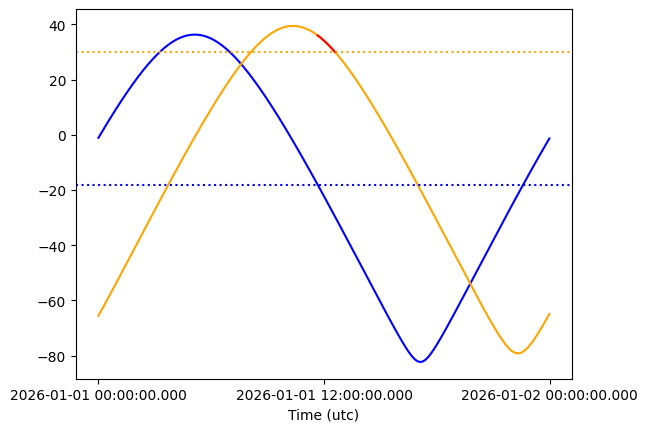

In [88]:
plt.plot(night_epochs,sun_altazes.alt.value,c="blue")
plt.plot(night_epochs,coord_altazes.alt.value,c="orange")
plt.plot(night_epochs[observable_indices],coord_altazes.alt.value[observable_indices],c="red")
plt.axhline(-18,c="blue",ls="dotted")
plt.axhline(30,c="orange",ls="dotted")
plt.show()

In [139]:
dec_grid = np.arange(-20,95,5)
ra_grid = np.arange(0,360,20)
location = EarthLocation(lat=30.6797,lon=104.0247,height=2_077)

year_start = Time("2026-01-01 00:00:00")
year_nights = year_start+(np.arange(0,365,1)*u.day)
night_epoch_additions = (np.arange(0,24*60,1)*u.minute)

min_coord_alt = 30.0 *u.deg
max_sun_alt =  -18.0 *u.deg

visibles = []

for dec in [55]:#dec_grid:
    for ra in ra_grid:
        ra_visibles = []
        coord = SkyCoord(ra=ra,dec=dec,frame="icrs",unit="degree")
        for night in year_nights:
            night_epochs = night+night_epoch_additions
            altaz_frames = AltAz(obstime=night_epochs,location=location)
            coord_altazes = coord.transform_to(altaz_frames)
            sun_altazes = get_sun(night_epochs).transform_to(altaz_frames)
            is_night = sun_altazes.alt < max_sun_alt
            is_coord_visible = coord_altazes.alt > min_coord_alt
            observable_indices = np.where(is_night & is_coord_visible)[0]
            if len(night_epochs[observable_indices])>0:
                ra_visibles.append((dec,ra,night,len(night_epochs[observable_indices])))
            #print(night)
        visibles.append(ra_visibles)

In [147]:
for i in range(0,len(visibles)):
    print(len(visibles[i]))

292
284
281
279
278
279
278
280
284
291
304
318
327
333
332
328
318
305


In [149]:
visibles[0][0]

(55,
 np.int64(0),
 <Time object: scale='utc' format='iso' value=2026-01-01 00:00:00.000>,
 242)

In [148]:
6400/(((1042000/5/365)*2135)/1024/1024/1024)

5637377.4556765715

In [ ]:
image_budget_gb_60s = 6400/((10*60))
image_budget_gb_1s = 22000/(10*60*60)
image_size_gb = (((122*1024*1024*1024)/(32*32))*2135)/1024/1024/1024

print(((image_budget_gb_60s/image_size_gb))*127926272)
print(((image_budget_gb_1s/image_size_gb))*127926272)

5364518.090241998
307342.1822534479


In [ ]:
image_budget_gb_60s = 6400/((10*60))
image_budget_gb_1s = 22000/(10*60*60)
image_size_gb = (((122*1024*1024*1024)/(32*32))*2135)/1024/1024/1024

print(((image_budget_gb_60s/image_size_gb))*127926272)
print(((image_budget_gb_1s/image_size_gb))*127926272)

5364518.090241998
307342.1822534479


In [119]:
image_budget_gb_60s = 6400/((10*60))
image_budget_gb_1s = 22000/(10*60*60)
image_size_gb = (((122*1024*1024*1024)/(32*32))*2135)/1024/1024/1024

print(((image_budget_gb_60s/image_size_gb))*127926272)
print(((image_budget_gb_1s/image_size_gb))*127926272)

5364518.090241998
307342.1822534479


In [120]:
print(((image_budget_gb_60s/image_size_gb))*453_810_816)


19030307.800883017


In [121]:
19030307/5364518

3.54744023601002

In [97]:
cam_gpixel = 122
minipix_per_cam = ((122*1024*1024*1024)**(1/2))/32
minipix_per_cam**2

127926272.00000001

In [95]:
(np.cos(np.deg2rad(55)))*18573500

np.float64(10653321.940566156)

In [137]:
(360*0.8)*180

51840.0